# L5 — Does evaporation change the answer? A water balance next to P30

*Krops weather notebooks · 3 of 3 · [1 — L5 water stress](01_L5_water_stress.ipynb) · [2 — L8 spreading window](02_L8_spreading_window.ipynb)*

**Status: iteration 2+ hypothesis.** Nothing here changes the L5 rule: `water_stress = p30_mm < 60` stays as decided, from WeatherKit history first with checked NASA POWER as the fallback.

## Problem statement

L5 asks one question of the weather: did less than 60 mm of rain fall in the last 30 days (P30)? That counts only what came in. A palm also loses water to the air, and how much depends on heat and sunshine: 60 mm in a hot, bright month leaves the soil drier than 60 mm in a cloudy one. A **water balance** (rain minus the reference evapotranspiration, ET0) counts both.

The backend now stores NASA POWER's daily temperature (`T2M`, `T2M_MAX`, `T2M_MIN`) next to the irradiance it already logged, so a water balance could run later without a new data source. Before anyone proposes one, we should know whether it would flag *different days* from P30 at all.

**The question:** over the same 1,444 days notebook 1 used, how many days does a 30-day water-balance deficit flag differently from `P30 < 60`?

## Thinking flow

1. Rebuild notebook 1's 1,444 days
2. What temperature and sunlight do we have?
3. Is our Ra right?
4. How much water does the air take? ET0 three ways
5. P30 < 60 against a 30-day deficit: how many days differ?
6. Rain between scans (the L2 helper on the same history)
7. Where this leaves us

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import krops_rules as rules
import krops_weather as kw
import l2_scan_rain as l2
import l5_water_balance as wb
import solar
from krops_weather import LAT, LON, SITE_NAME

kw.use_chart_style()
AS_OF = date(2026, 10, 11)       # notebook 1's run: everything below uses that day's saved responses
RAIN_END = date(2026, 10, 8)     # NASA POWER's last day of rain in that run
WK_FROM = date(2021, 8, 1)       # WeatherKit history starts here
ELEVATION_M = 4.63               # NASA POWER's elevation for this point (from its response)
P30_MM = rules.P30_THRESHOLD_MM  # the decided L5 line, unchanged
print(f"{SITE_NAME}: {LAT}, {LON} · data as of {AS_OF} · P30 line {P30_MM} mm · water-balance line {wb.WB30_DEFICIT_MM} mm (GUESS)")

Tanjung Pinang: 0.92, 104.45 · data as of 2026-10-11 · P30 line 60.0 mm · water-balance line 0.0 mm (GUESS)


### 1. Rebuild notebook 1's 1,444 days

**Why we ask.** If the days differ, any difference in the flags could come from the data rather than the method. So this notebook reads the responses notebook 1 saved on 11 Oct (`forever=True` reuses them instead of asking again), runs the same monthly check on NASA POWER, and requires exactly the same 1,444 days where both sources have a full 30-day window.

In [2]:
history, _, _ = kw.fetch_nasa_power(date(1991, 1, 1), date(2025, 12, 31), params=("PRECTOTCORR",))
this_year, _, _ = kw.fetch_nasa_power(date(2026, 1, 1), AS_OF, forever=True)  # notebook 1's 11 Oct request
nasa_all = pd.concat([history["PRECTOTCORR"], this_year["PRECTOTCORR"]]).dropna()
nasa_all = nasa_all[~nasa_all.index.duplicated(keep="last")].sort_index()

wk = kw.fetch_weatherkit_history(WK_FROM, RAIN_END, forever=True)  # notebook 1's 10-day requests
wk_rain = wk["rain_mm"].dropna()

check = kw.suspect_months(nasa_all[nasa_all.index >= WK_FROM], kw.monthly_normals(nasa_all), wk_rain)
nasa_ok = kw.drop_months(nasa_all, check.index[check["suspect"]])


def rolling_30(daily):
    """Sum over each full 30-day window, by the day it ends (a window with a missing day gives nothing)."""
    daily = daily.dropna().copy()
    daily.index = pd.to_datetime(daily.index)
    return daily.rolling("30D", min_periods=30).sum()


p30 = pd.concat({"WeatherKit": rolling_30(wk_rain), "NASA POWER": rolling_30(nasa_ok)}, axis=1, sort=True).dropna()
assert len(p30) == 1444, f"expected notebook 1's 1,444 days, got {len(p30)}"
missing_wk = sorted(set(pd.date_range(WK_FROM, RAIN_END).date) - set(wk_rain.index))
print(f"{len(p30)} days, {p30.index.min():%d %b %Y} to {p30.index.max():%d %b %Y} · suspect NASA months: {int(check['suspect'].sum())}"
      f" · WeatherKit days missing: {', '.join(f'{d:%d %b %Y}' for d in missing_wk) or 'none'}")
print(f"P30 < {P30_MM:g} mm: WeatherKit {int((p30['WeatherKit'] < P30_MM).sum())} days, NASA POWER {int((p30['NASA POWER'] < P30_MM).sum())} days")

1444 days, 30 Aug 2021 to 08 Oct 2026 · suspect NASA months: 11 · WeatherKit days missing: 01 Jun 2023
P30 < 60 mm: WeatherKit 15 days, NASA POWER 0 days


**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- The same **1,444 days** as notebook 1 (30 Aug 2021 to 8 Oct 2026), the same 11 suspect NASA POWER months, and the same flag counts: `P30 < 60` on **15 days** from WeatherKit and on **none** from checked NASA POWER.
- WeatherKit's saved history is missing **1 Jun 2023** (notebook 2's request for the same weeks has it). That one gap removes 30 windows; filled, there would be 1,474 days. The rules treat it as they should: no P30 for those windows, never a day of 0 mm.

### 2. What temperature and sunlight do we have?

**Why we ask.** Hargreaves ET0 runs on the daily maximum and minimum temperature, and leans hard on the gap between them (it enters as √(Tmax − Tmin)). Priestley–Taylor runs on measured sunlight. Two temperature sources are at hand:

| Source | What | Notes |
| --- | --- | --- |
| **NASA POWER** `T2M_MAX`, `T2M_MIN`, `T2M` | The same ~55 × 70 km cell as its rain | What the backend now stores. One request, saved to `data/raw/` |
| **WeatherKit** `temperatureMax`, `temperatureMin` | In every history response we already fetch for rain | No extra requests, but Apple's terms for storing it are unchecked, so the job doesn't keep it |

Sunlight is NASA POWER's `ALLSKY_SFC_SW_DWN`, the value the job has always logged.

In [3]:
met, met_units, met_sources = kw.fetch_nasa_power(
    date(2021, 7, 2), RAIN_END,
    params=("T2M", "T2M_MAX", "T2M_MIN", "ALLSKY_SFC_SW_DWN", "CLRSKY_SFC_SW_DWN", "TOA_SW_DWN"), forever=True)
print("NASA POWER made from:", met_sources)
print("Units:", met_units)

window = pd.date_range(p30.index.min() - pd.Timedelta(days=29), p30.index.max()).date
temps = pd.DataFrame({
    "NASA POWER Tmax": met["T2M_MAX"], "NASA POWER Tmin": met["T2M_MIN"],
    "WeatherKit Tmax": wk["tmax_c"], "WeatherKit Tmin": wk["tmin_c"],
}).reindex(window)
summary = pd.DataFrame({
    "days with a value": temps.notna().sum(),
    "mean (°C)": temps.mean().round(1),
})
display(summary)
ranges = pd.DataFrame({"NASA POWER": temps["NASA POWER Tmax"] - temps["NASA POWER Tmin"],
                       "WeatherKit": temps["WeatherKit Tmax"] - temps["WeatherKit Tmin"]})
display(ranges.describe().loc[["mean", "min", "50%", "max"]].round(1).rename(index={"50%": "median"})
        .rename_axis("Tmax − Tmin (°C)"))
print(f"Days with ALLSKY: {met['ALLSKY_SFC_SW_DWN'].reindex(window).notna().sum()} of {len(window)}")

NASA POWER made from: ['GEOSIT', 'FLASHFLUX', 'MERRA2', 'SYN1DEG', 'POWER']
Units: {'T2M': 'C', 'T2M_MAX': 'C', 'T2M_MIN': 'C', 'ALLSKY_SFC_SW_DWN': 'MJ/m^2/day', 'CLRSKY_SFC_SW_DWN': 'MJ/m^2/day', 'TOA_SW_DWN': 'MJ/m^2/day'}


,days with a value,mean (°C)
NASA POWER Tmax,1895,29.3
NASA POWER Tmin,1895,27.4
WeatherKit Tmax,1894,30.1
WeatherKit Tmin,1894,26.1


,NASA POWER,WeatherKit
Tmax − Tmin (°C),,
mean,1.9,4.0
min,0.5,0.8
median,1.8,4.0
max,4.5,6.7


Days with ALLSKY: 1895 of 1895


**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- Both sources cover the whole window: 1,895 days from NASA POWER, 1,894 from WeatherKit (the same missing day).
- **NASA POWER's day–night range is tiny: 1.9 °C on average** (median 1.8, never over 4.5 °C), with nights averaging 27.4 °C. WeatherKit's range is **4.0 °C**, with nights at 26.1 °C.
- That is the sea. NASA POWER's cell is mostly water (notebook 1, step 2), and air over the sea barely cools at night. A land station in the humid tropics usually records a wider range; BMKG's station Tmax/Tmin would say how much wider at Tanjung Pinang.

**This matters for what the backend now stores.** The job keeps NASA POWER's `T2M`, `T2M_MAX` and `T2M_MIN` for every cell. In a coastal cell they describe the sea more than the plot, so anything built on them later needs this check first.

### 3. Is our Ra right?

**Why we ask.** Both ET0 methods need Ra, the sunlight at the top of the atmosphere, which `solar.py` computes from latitude and day of year (FAO-56). NASA POWER publishes its own (`TOA_SW_DWN`), computed independently. If the two agree, the Ra under every ET0 below is sound.

In [4]:
ra = pd.Series({d: solar.extraterrestrial_daily(LAT, solar.day_of_year(d)) for d in window}, name="Ra")
toa = met["TOA_SW_DWN"].reindex(window)
rel = ((ra - toa) / toa * 100).dropna()
print(f"{len(rel)} days · Ra (solar.py) − TOA (NASA POWER): median {rel.median():+.2f}%, "
      f"range {rel.min():+.2f}% to {rel.max():+.2f}% · Ra {ra.min():.1f}–{ra.max():.1f} MJ/m²/day")

1895 days · Ra (solar.py) − TOA (NASA POWER): median +0.39%, range -0.52% to +1.09% · Ra 33.7–37.9 MJ/m²/day


**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- `solar.py`'s Ra and NASA POWER's own top-of-atmosphere sunlight agree within **−0.5% to +1.1%** (median +0.4%) on all 1,895 days. The small seasonal gap is FAO-56's simple declination formula, the one Hargreaves was calibrated with.

Ra is sound; none of the uncertainty below comes from it.

### 4. How much water does the air take? ET0 three ways

**What we did.** Daily ET0 from `l5_water_balance.py`:

| Method | Inputs | Notes |
| --- | --- | --- |
| **Hargreaves, NASA POWER temperature** | Tmax, Tmin, Ra | **The main one below:** what the backend could run from what it now stores |
| Hargreaves, WeatherKit temperature | Tmax, Tmin, Ra | Same method, ~10 km temperature |
| Priestley–Taylor, NASA POWER | ALLSKY, Tmax, Tmin, Ra | Driven by sunlight rather than the day–night range |

All constants are FAO-56's (Priestley–Taylor's α = 1.26 from the 1972 paper). Hargreaves is known to read high in humid climates, where a small day–night range understates the clouds.

ET0, mm/day, mean over the window: Hargreaves, NASA POWER temperature 2.10, Hargreaves, WeatherKit temperature 3.08, Priestley–Taylor, NASA POWER 4.63
ET0 over 30 days, mm (median of every 30-day sum): Hargreaves, NASA POWER temperature 62, Hargreaves, WeatherKit temperature 93, Priestley–Taylor, NASA POWER 138


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
"Hargreaves, NASA POWER temperature",2.04,2.19,2.31,2.24,2.02,1.85,1.93,2.08,2.31,2.26,2.06,1.92
"Hargreaves, WeatherKit temperature",2.99,3.30,3.42,3.26,3.02,2.76,2.78,2.96,3.13,3.27,3.14,2.98
"Priestley–Taylor, NASA POWER",4.25,5.01,5.15,5.09,4.73,4.28,4.69,4.65,4.69,4.80,4.06,4.13


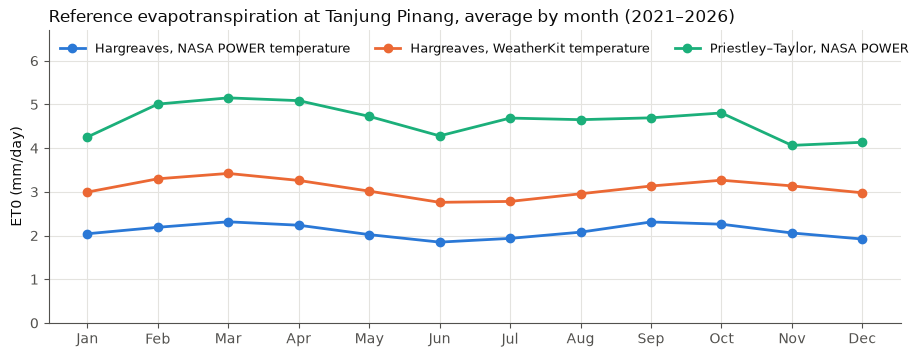

In [5]:
rows = pd.DataFrame({"ra": ra, "tmax": met["T2M_MAX"].reindex(window), "tmin": met["T2M_MIN"].reindex(window),
                     "rs": met["ALLSKY_SFC_SW_DWN"].reindex(window),
                     "wk_tmax": wk["tmax_c"].reindex(window), "wk_tmin": wk["tmin_c"].reindex(window)})


def daily(fn, *cols):
    ok = rows[list(cols)].notna().all(axis=1)
    return pd.Series([fn(*r) for r in rows.loc[ok, list(cols)].itertuples(index=False)], index=rows.index[ok])


METHODS = ["Hargreaves, NASA POWER temperature", "Hargreaves, WeatherKit temperature", "Priestley–Taylor, NASA POWER"]
et0 = pd.DataFrame({
    METHODS[0]: daily(wb.hargreaves_et0, "tmax", "tmin", "ra"),
    METHODS[1]: daily(wb.hargreaves_et0, "wk_tmax", "wk_tmin", "ra"),
    METHODS[2]: daily(lambda rs, tx, tn, r: wb.priestley_taylor_et0(rs, tx, tn, r, ELEVATION_M), "rs", "tmax", "tmin", "ra"),
})
monthly = et0.groupby(pd.to_datetime(et0.index).month).mean()
monthly.index = pd.to_datetime([f"2000-{m}-1" for m in monthly.index]).strftime("%b")
print("ET0, mm/day, mean over the window:", ", ".join(f"{m} {v:.2f}" for m, v in et0.mean().items()))
print("ET0 over 30 days, mm (median of every 30-day sum):",
      ", ".join(f"{m} {rolling_30(et0[m]).median():.0f}" for m in METHODS))
display(monthly.round(2).T)

colors = [kw.NASA_COLOR, kw.WK_COLOR, kw.THIRD_COLOR]
fig, ax = plt.subplots(figsize=(11, 3.8))
for name, color in zip(METHODS, colors):
    ax.plot(range(12), monthly[name], color=color, linewidth=2, marker="o", markersize=6, label=name)
ax.set_xticks(range(12), monthly.index)
ax.set_ylim(0, monthly.max().max() * 1.3)
ax.set_ylabel("ET0 (mm/day)")
ax.set_title(f"Reference evapotranspiration at {SITE_NAME}, average by month (2021–2026)", loc="left")
ax.legend(loc="upper left", ncol=3, fontsize=9)
plt.show()

**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- The three methods disagree by a factor of two: **2.1 mm/day** (Hargreaves on NASA POWER temperature), **3.1** (Hargreaves on WeatherKit temperature) and **4.6** (Priestley–Taylor on NASA POWER sunlight). Over 30 days that is a median of about 62, 93 and 138 mm.
- Hargreaves follows the day–night range, so NASA POWER's sea-flattened range gives the lowest ET0. The usual caution about Hargreaves (it reads *high* in humid climates) points the other way here: the range it is fed is wrong. Priestley–Taylor follows sunlight and peaks in February–April.
- **Without measured weather we can't say which level is right.**

What every method agrees on: **ET0 is flat through the year.** Monthly averages stay within about ±12% of each method's mean. That decides step 5.

### 5. P30 < 60 against a 30-day deficit: how many days differ?

**Why we ask.** This is the question the notebook exists for. For every one of the 1,444 days, compare the decided flag (`P30 < 60`) with a water-balance flag, `WB30 = Σ(rain − ET0) over the same 30 days < WB30_DEFICIT_MM`.

**Two thresholds, because the second one is a guess.**

- **The GUESS line, 0 mm** (`WB30_DEFICIT_MM`, no source yet): the 30 days' rain didn't cover the 30 days' ET0.
- **A rate-matched line:** the WB30 value that flags *exactly as many days* as `P30 < 60` does. At that line both rules raise the flag equally often, so the days that still differ show what ET0 changes, not where the line was drawn.

Rain comes from WeatherKit (L5's first source) and from checked NASA POWER; ET0 from Hargreaves with NASA POWER temperature. The pandas backcast is checked against `l5_water_balance.water_balance` on a sample of days.

In [6]:
main_et0 = et0[METHODS[0]]
rain_sources = {"WeatherKit": wk_rain, "NASA POWER": nasa_ok}


def wb30(rain, et0_daily):
    both = pd.concat({"rain": rain, "et0": et0_daily}, axis=1, sort=True).dropna()
    return rolling_30(both["rain"] - both["et0"]).reindex(p30.index)


def compare(p, w, label, threshold):
    fp, fw = p < P30_MM, w < threshold
    return {"rain": label[0], "line": label[1], "WB30 line (mm)": round(threshold, 1),
            "P30 < 60 (days)": int(fp.sum()), "WB30 deficit (days)": int(fw.sum()), "both": int((fp & fw).sum()),
            "P30 only": int((fp & ~fw).sum()), "WB30 only": int((~fp & fw).sum()), "days that differ": int((fp != fw).sum())}


def rate_matched(p, w):
    k = int((p < P30_MM).sum())
    return None if k == 0 else float(w.sort_values().iloc[k])  # strictly under the (k+1)-th lowest → k days


results, balances = [], {}
for name, rain in rain_sources.items():
    w = wb30(rain, main_et0)
    assert w.notna().all(), f"{name}: no balance on {int(w.isna().sum())} of the 1,444 days"
    balances[name] = w
    results.append(compare(p30[name], w, (name, "GUESS 0 mm"), wb.WB30_DEFICIT_MM))
    t = rate_matched(p30[name], w)
    if t is not None:
        results.append(compare(p30[name], w, (name, "rate-matched"), t))

# The pandas backcast must agree with the module L5 would port
rain_d, et0_d = wk_rain.to_dict(), main_et0.to_dict()
for end in p30.index[::97]:
    assert abs(wb.water_balance(rain_d, et0_d, end.date()) - balances["WeatherKit"][end]) < 0.06, end

table = pd.DataFrame(results).set_index(["rain", "line"])
display(table)

sensitivity = []
for method in METHODS:
    w = wb30(wk_rain, et0[method])
    row = compare(p30["WeatherKit"], w, ("WeatherKit", "GUESS 0 mm"), wb.WB30_DEFICIT_MM)
    t = rate_matched(p30["WeatherKit"], w)
    row_rm = compare(p30["WeatherKit"], w, ("WeatherKit", "rate-matched"), t)
    sensitivity.append({"ET0": method, "days with a balance": int(w.notna().sum()),
                        "WB30 deficit at 0 mm (days)": row["WB30 deficit (days)"],
                        "differ at 0 mm": row["days that differ"],
                        "rate-matched line (mm)": round(t, 1), "differ, rate-matched": row_rm["days that differ"]})
print("WeatherKit rain, by ET0 method:")
display(pd.DataFrame(sensitivity).set_index("ET0"))

# Why: how much does 30-day ET0 move, next to how much P30 moves?
spread = pd.DataFrame({"P30, WeatherKit": p30["WeatherKit"]}
                      | {f"ET0 over 30 days: {m}": rolling_30(et0[m]).reindex(p30.index) for m in METHODS})
display(spread.quantile([0.05, 0.5, 0.95]).T.round(0).rename(columns={0.05: "5%", 0.5: "median", 0.95: "95%"})
        .rename_axis("mm over 30 days"))
print("Rank correlation of P30 with WB30 (WeatherKit rain):",
      ", ".join(f"{m} {kw.rank_corr(p30['WeatherKit'], wb30(wk_rain, et0[m]))}" for m in METHODS))

WB30 line (mm)  P30 < 60 (days)  WB30 deficit (days)  \
rain       line                                                                 
WeatherKit GUESS 0 mm               0.0               15                   17   
           rate-matched            -1.5               15                   15   
NASA POWER GUESS 0 mm               0.0                0                    0   

                         both  P30 only  WB30 only  days that differ  
rain       line                                                       
WeatherKit GUESS 0 mm      15         0          2                 2  
           rate-matched    15         0          0                 0  
NASA POWER GUESS 0 mm       0         0          0                 0

WeatherKit rain, by ET0 method:


,days with a balance,WB30 deficit at 0 mm (days),differ at 0 mm,rate-matched line (mm),"differ, rate-matched"
ET0,,,,,
"Hargreaves, NASA POWER temperature",1444,17,2,-1.5,0
"Hargreaves, WeatherKit temperature",1444,53,38,-32.2,0
"Priestley–Taylor, NASA POWER",1444,305,290,-92.2,0


,5%,median,95%
mm over 30 days,,,
"P30, WeatherKit",97.0,214.0,444.0
"ET0 over 30 days: Hargreaves, NASA POWER temperature",54.0,62.0,71.0
"ET0 over 30 days: Hargreaves, WeatherKit temperature",83.0,93.0,102.0
"ET0 over 30 days: Priestley–Taylor, NASA POWER",116.0,136.0,156.0


Rank correlation of P30 with WB30 (WeatherKit rain): Hargreaves, NASA POWER temperature 1.0, Hargreaves, WeatherKit temperature 1.0, Priestley–Taylor, NASA POWER 0.99


WeatherKit rain, flagged days by the month the window ends:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
days,124,84,93,91,124,90,124,126,151,163,150,124
P30 < 60,0,5,0,0,0,0,0,10,0,0,0,0
WB30 < 0 (GUESS),0,6,0,0,0,0,0,11,0,0,0,0
WB30 rate-matched,0,5,0,0,0,0,0,10,0,0,0,0


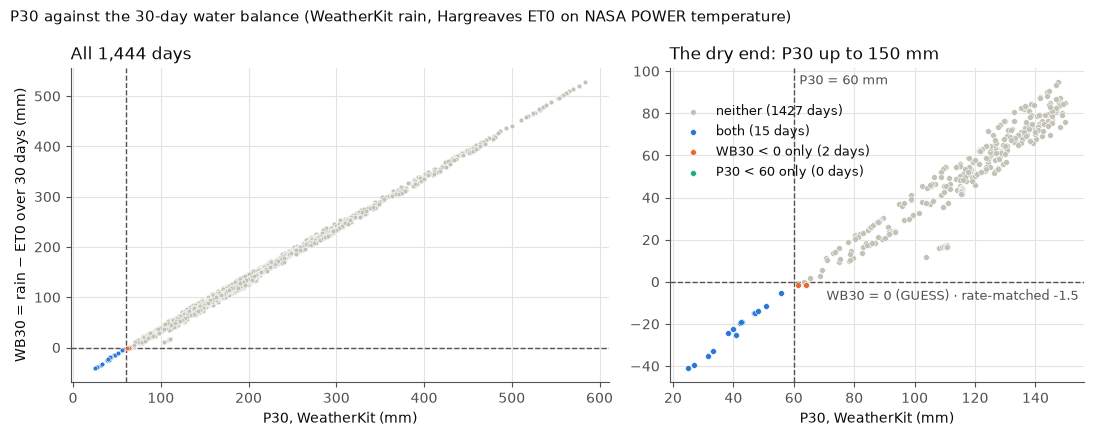

In [7]:
w, p = balances["WeatherKit"], p30["WeatherKit"]
line = rate_matched(p, w)
by_month = pd.DataFrame({
    "days": p.groupby(p.index.month).size(),
    "P30 < 60": (p < P30_MM).groupby(p.index.month).sum(),
    "WB30 < 0 (GUESS)": (w < wb.WB30_DEFICIT_MM).groupby(w.index.month).sum(),
    "WB30 rate-matched": (w < line).groupby(w.index.month).sum(),
}).astype(int)
by_month.index = pd.to_datetime([f"2000-{m}-1" for m in by_month.index]).strftime("%b")
print("WeatherKit rain, flagged days by the month the window ends:")
display(by_month.T)

fp, fw = p < P30_MM, w < wb.WB30_DEFICIT_MM
groups = [("neither", ~fp & ~fw, kw.REMOVED), ("both", fp & fw, kw.NASA_COLOR),
          ("WB30 < 0 only", ~fp & fw, kw.WK_COLOR), ("P30 < 60 only", fp & ~fw, kw.THIRD_COLOR)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, dry_end in zip(axes, (False, True)):
    for label, mask, color in groups:
        shown = mask & (p <= 150) if dry_end else mask
        ax.scatter(p[shown], w[shown], s=18 if dry_end else 12, color=color, edgecolor="white", linewidth=0.4,
                   label=f"{label} ({int(mask.sum())} days)", zorder=3)
    ax.axvline(P30_MM, color=kw.MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.axhline(wb.WB30_DEFICIT_MM, color=kw.MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.set_xlabel("P30, WeatherKit (mm)")
axes[0].set_ylabel("WB30 = rain − ET0 over 30 days (mm)")
axes[0].set_title("All 1,444 days", loc="left")
axes[1].set_title("The dry end: P30 up to 150 mm", loc="left")
axes[1].annotate(f"P30 = {P30_MM:g} mm", (P30_MM, axes[1].get_ylim()[1]), xytext=(4, -12), textcoords="offset points",
                 color=kw.MUTED, fontsize=9)
axes[1].annotate(f"WB30 = 0 (GUESS) · rate-matched {line:.1f}", (axes[1].get_xlim()[1], 0), xytext=(-4, -13),
                 textcoords="offset points", ha="right", color=kw.MUTED, fontsize=9)
axes[1].legend(loc="upper left", bbox_to_anchor=(0.0, 0.92), fontsize=9)
fig.suptitle("P30 against the 30-day water balance (WeatherKit rain, Hargreaves ET0 on NASA POWER temperature)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- **At the GUESS line (0 mm)** the water balance flags 17 days to P30's 15. Both flag the same 15; the balance adds 2. With the other ET0 methods the GUESS line flags 53 or 305 days, but that only reflects how much ET0 each subtracts: `WB30 < 0` is roughly `P30 < 30-day ET0`, about 62, 93 or 136 mm on these days.
- **At the rate-matched line, 0 days differ, for all three ET0 methods.** When the two rules flag as many days as each other, they flag the same days.
- The spread table says why. Over 30 days, ET0 moves by only **17–40 mm** between its 5th and 95th percentiles, while P30 moves by about **350 mm** (97 to 444). The balance is P30 minus a near-constant, so it ranks the days exactly as P30 does (rank correlation 0.99–1.0).
- With checked NASA POWER rain neither rule ever fires: its P30 never drops under 60 mm on these days (notebook 1, step 4).
- Both flags fire only in **February and August**, the dry seasons notebook 1 found.

**At this site, rain − ET0 adds nothing that P30 doesn't already know.** A water balance would only move the line, and the line is a decided value. The open questions for L5 are still notebook 1's: is the rain right, and is 60 mm the right line for Bintan? Measured rain answers both; ET0 doesn't.

**How far this goes.** One site, five years, 15 flagged days in two dry spells, at a place where it rains most of the year. Where the dry season is longer and ET0 swings more between months, a balance could rank days differently. Re-run this before ruling it out for Krops in general.

### 6. Rain between scans (the L2 helper on the same history)

**Why we ask.** L2 compares crowns between two scans. Part of any change is the weather in between, so L2 will want the rain between the scans and P30 as it stood at each one. `l2_scan_rain.py` provides both: P30 goes through `rules.choose_p30` unchanged with the scan date as "today", and the rain between two scans comes from one source only (the first in L5's order that has every day). The backend doesn't see scan dates yet, so here are made-up quarterly scans on the trial plot's history.

In [8]:
scans = [date(y, m, 1) for y in range(2022, 2027) for m in (2, 5, 8, 11) if date(y, m, 1) <= AS_OF]
sources = {"weatherkit-history": wk_rain.to_dict(), "nasa-power": nasa_ok.dropna().to_dict()}
log = l2.scan_rain_log(sources, scans)
scan_table = pd.DataFrame([{
    "scan": e["scan_date"],
    "P30 (mm)": e["p30"]["p30_mm"], "P30 source": e["p30"]["p30_source"], "quality": e["p30"]["p30_quality"],
    "water_stress": e["p30"]["water_stress"],
    "rain since last scan (mm)": e["since_previous"] and e["since_previous"]["rain_mm"],
    "days": e["since_previous"] and e["since_previous"]["days"],
    "from": e["since_previous"] and e["since_previous"]["source"],
} for e in log]).set_index("scan")
scan_table["days"] = scan_table["days"].astype("Int64")
display(scan_table)

,P30 (mm),P30 source,quality,water_stress,rain since last scan (mm),days,from
scan,,,,,,,
2022-02-01,82.9,weatherkit-history,ok,False,NaN,<NA>,NaN
2022-05-01,257.1,weatherkit-history,ok,False,654.6,89,weatherkit-history
2022-08-01,153.7,weatherkit-history,ok,False,596.2,92,weatherkit-history
2022-11-01,299.8,weatherkit-history,ok,False,768.0,92,weatherkit-history
2023-02-01,314.5,weatherkit-history,ok,False,1021.9,92,weatherkit-history
2023-05-01,208.0,weatherkit-history,ok,False,634.1,89,weatherkit-history
2023-08-01,262.4,weatherkit-history,ok,False,730.8,92,nasa-power
2023-11-01,139.2,weatherkit-history,ok,False,435.7,92,weatherkit-history
2024-02-01,420.2,weatherkit-history,ok,False,1191.9,92,weatherkit-history


**What we found** *(run on 14 Oct 2026, on the responses saved 11 Oct)*

- 19 quarterly scans from Feb 2022 to Aug 2026. Every P30 comes from WeatherKit with quality `ok`. One scan is flagged: **1 Feb 2026, P30 = 33.4 mm**, in the dry spell notebook 1 found.
- Rain between scans runs from **347 mm** (May–Aug 2025) to **1,213 mm** (Nov 2024 – Feb 2025).
- **May–Aug 2023 comes from NASA POWER.** WeatherKit is missing 1 Jun 2023, so the whole interval switches source instead of mixing the two. Every other interval is WeatherKit.

To run on real scans, the backend needs the scan dates (from the app, at sync) and more rain history than the 37 days it keeps today (plan item 6).

### Where this leaves us *(run on 14 Oct 2026, data as of 11 Oct)*

| | Status |
| --- | --- |
| Same 1,444 days as notebook 1, from the saved responses | Verified (asserted) |
| `solar.py` Ra against NASA POWER's `TOA_SW_DWN` | Verified: within −0.5% to +1.1% |
| NASA POWER temperature at this cell | **Sea-dominated:** day–night range 1.9 °C (WeatherKit 4.0 °C) |
| ET0 level | **Open:** 2.1–4.6 mm/day depending on method; needs measured weather |
| Does rain − ET0 flag different days from `P30 < 60`? | **No, at this site:** 0 days differ at a rate-matched line, all three methods |
| Days that differ at the GUESS 0 mm line | 2 with the main method; 38 and 290 with the others (a threshold effect) |
| L2 helpers on four years of history | Work; one interval fell back to NASA POWER, as designed |

**Recommendations**
- **Keep the L5 rule as it is.** At Tanjung Pinang a water balance only moves the line, so it isn't worth a new rule or a new on-device calculation in iteration 2.
- **Keep storing temperature, but don't use NASA POWER's in a coastal cell** until it has been compared with BMKG's station Tmax/Tmin. WeatherKit's temperature, already in every response the job fetches, is the likelier source, pending Apple's terms.
- **Re-run this notebook at a site with a longer dry season** before ruling a water balance out for Krops in general.
- Measured rain (BMKG or the gauge) is still the most useful next data for L5, as notebook 1 concluded.

### Open questions

- **Is NASA POWER's temperature usable near the coast?** Compare it with BMKG's station Tmax/Tmin at Tanjung Pinang, and count how many Krops cells are mostly sea.
- **Which ET0 level is right here?** Needs measured weather: BMKG station temperature, humidity and sunshine or radiation.
- **May Krops store WeatherKit's temperature?** It arrives with every rain request; Apple's terms for storing WeatherKit data are still unchecked.
- **Does the result hold at a drier site?** Where ET0 varies more from month to month, a balance could rank days differently from P30.
- `WB30_DEFICIT_MM = 0` is a guess with no source. It only matters if a water balance is ever proposed as a rule.

---
**Attribution.** Weather data: Apple Weather — [other data sources](https://developer.apple.com/weatherkit/data-source-attribution/). These data were obtained from the NASA Langley Research Center (LaRC) POWER Project funded through the NASA Earth Science/Applied Science Program. Methods: Allen et al. (1998), FAO Irrigation and Drainage Paper 56; Hargreaves & Samani (1985); Priestley & Taylor (1972); ASCE-EWRI (2005) for the cloudiness bound. Raw API responses stay in `data/raw/` (git-ignored).